---
title: Scaling Decision Analysis with Hyperbolic Trade Space Identification
abstract: |
  A trade study must produce an answer and a justification an accountable executive can follow.
  Principal component analysis (PCA) is trusted as reproducible and interpretable, and explains
  variance. We explain tensions. A fitted posynomial reference surface models
  the data underlying the table, not the Pareto boundary, and gives the data a coordinate system;
  the table and its reading are views of that model. It is fitted to the outer edge of the data, not
  through its middle: a soft support that a few designs may exceed, not a regression. A reversible chart separates a design's position along
  the surface from its energy differential: its level relative to the surface, by analogy with a
  potential, not a physical energy. Each facet reports
  its contending metrics, an n-lemma (by analogy with dilemma and trilemma), with elasticities:
  the percentage of one metric given up per percentage gained in another. Modelling a single
  n-lemma fits a monomial, which transforms into a convex program and is solved directly; when
  several trade-offs are active at once the model is a posynomial, compatible with generalized
  geometric programming (GGP); any kernel that keeps that compatibility generalizes the method.
  Like PCA, our method is unsupervised feature engineering; the two answer different
  questions and compose, as when PCA is run on the chart. On a cubesat model coupling power, mass and attitude control, one facet blends
  the subsystems' trade-offs into a single tension; three facets separate the contending sets.
---

In [1]:
import paper_paths  # puts the repository and examples/adcs on sys.path

paper_paths.inline_figures()

In [2]:
import case

study = case.load_study("primary")

In [3]:
fits = case.k_fits(study)

(sect-problem)=
## The decision problem

Decision analysis has two products: an answer, and a justification an accountable executive can follow and defend. It seeks responsible choice among conflicting objectives [@keeney1993decisions] and clear conversation with the decision-maker [@howard1988decision]. The justification is the hard product: the process turning much data into little must be recognized, reproducible, rigorous.

A trade study is a document: a grid, a table, a ranking by weighted criteria; surveys compare them [@baker2012survey]. The weights are human judgments, susceptible to bias in trade studies [@smith2007ameliorating; @chilli2026decision]. Systems engineering is moving from document-based [@henderson2021value] to model-based practice [@madni2018model], but the computational alternatives are bespoke and opaque. To displace it, a method must handle real data's scale, complexity and noise interpretably.

PCA reduces dimensionality and increases interpretability while minimizing information loss [@jolliffe2016principal]. But variance says where the data are free and nothing about trade-offs, which a decision-maker must know to defend a judgment.

We take PCA as inspiration and explain tensions where it explains variance. Objectives may align in one region and oppose in another. The fitted reference surface, a posynomial fitted to the data underlying the table, gives them a coordinate system: the chart, a reversible rewriting of the metrics as a position along the surface and a level relative to it. The surface is not the Pareto boundary, and the table and its reading are views ({prf:ref}`def-objects`). Each facet, a piece of the surface and not a set of designs, names the metrics that contend on it with elasticities: an n-lemma (by analogy with dilemma and trilemma). Like PCA, our method is unsupervised feature engineering; the two answer different questions and compose: {ref}`Appendix D.16 <sub-d-16>` reads the principal directions of the near-frontier chart as the trade-offs the sampling exercised, a reading and not a result. The workflow has two uses, design optimization, the setting of multidisciplinary design analysis and optimization [@martins2013multidisciplinary; @martins2021engineering], and configuration management, and in both a configuration is evaluated into attributes whose trade-offs the fit reads.

**Contribution.** Scaling up trade studies with a reproducible method. On this case, with the number of designs and of metrics, dominance stops shortlisting: its nondominated set nears the whole table.

In [4]:
from generate_findings import nondominated_sentence

nondominated_sentence(study)

'Of 706 feasible cubesat designs, the nondominated sets hold 126 on 4 and 659 on 9 attributes (counts that hold over five regenerations of the data under rounding-level perturbation; a number that moves over them is printed as a range, <a href="supporting-material/#sub-d-11" target="_self" style="color:inherit;text-decoration:underline">Appendix D.11</a>).'

**Main results** ({numref}`Section %s <sect-results>`; each has hypotheses, a sketch and a script).

1. The fitted reference surface is where the invariant value, a weighted geometric mean of the metrics that doubles when every metric doubles, equals one; it is not the Pareto boundary but the level from which every design's position and level, and each facet's elasticities, are read ({prf:ref}`thm-invariant`).
2. The one-facet fit is a geometric program, convex in the logarithmic variables ({prf:ref}`thm-kkt`, {prf:ref}`thm-convex`); its exponents are elasticities and its chart is reversible ({prf:ref}`thm-elasticity`, {prf:ref}`thm-chart`).
3. With one term the posynomial extension is the monomial, and a maximizer of V is Pareto-efficient ({prf:ref}`thm-extension`, {prf:ref}`thm-pareto`).
4. The several-facet fit, not convex in the terms, has three levels of guarantee and a stopping declaration ({prf:ref}`thm-soft`, {prf:ref}`thm-descent`, {prf:ref}`lem-gap`, {prf:ref}`lem-margin`, {prf:ref}`prop-local`); a soft fit has a second-order certificate ({prf:ref}`thm-certificate`).
5. PCA and the fit are chained: the principal directions of the near-frontier chart read the trade-offs the sampling exercised, a reading and not a result ({ref}`Appendix D.16 <sub-d-16>`).
6. Numerical: the status a fit reaches. Open: Q1 to Q4 and the search's monotonicity.
7. On a cubesat model coupling power, mass and attitude control the facets separate contending sets that one facet blends ({numref}`Section %s <sect-case-analysis>`).

**Organization.** Appendices: {ref}`A <appendix-a>` notation, {ref}`B <appendix-b>` proofs, {ref}`C <appendix-c>` model, {ref}`D <appendix-d>` results, {ref}`E <appendix-e>` assumptions, {ref}`F <appendix-f>` reproducibility, {ref}`G <appendix-g>` prior art.

(sect-prior-art)=
## Prior art, by family

We claim no priority. {numref}`Table %s <tab-families-1>` says what each family produces, what we share, how we differ and where to read it. {ref}`Appendix G <appendix-g>` is the larger register; it is not exhaustive and says for every entry what this work does differently, extends or adds.

In [5]:
from generate_prior_art import family_table

family_table()

Family and sources,Produces,Shares,Differs
Pareto and multiobjective optimizationMiettinen 1999; Ehrgott 2005; Zitzler and Thiele 1999; Deb et al. 2002,Returns a nondominated set of designs,the weights act as a trade-off,Returns no coordinate system and no exponents
Data envelopment analysis (DEA)Charnes et al. 1978; Banker et al. 1984; Andersen and Petersen 1993; Färe et al. 1994; Allen et al. 1997; Dyson et al. 2001,Evaluates the relative efficiency of each decision-making unit,"A one-sided envelope of the data, a score per unit",One exponent vector per facet
Production and distance functionsCobb and Douglas 1928; Shephard 1970; Färe and Primont 1995; Farrell 1957,"The Cobb-Douglas production form, and the Shephard distance function",the constant-returns Cobb-Douglas form,Attributes in place of inputs
Deterministic and stochastic frontiersAigner and Chu 1968; Afriat 1972; Richmond 1974; Greene 1980; Aigner et al. 1977; Battese 1992,Estimates frontier production functions,A one-sided criterion on log-linear residuals,A smooth soft maximum over a simplex-constrained geometric mean
Principal component analysis (PCA)Jolliffe and Cadima 2016,Finds uncorrelated components that successively maximize variance,an unsupervised summary in a few directions,"The criterion is a one-sided soft maximum, not variance"
Compositional and log-ratio PCAAitchison 1983; Aitchison 1986; Egozcue et al. 2003,PCA of compositional data,an isometric logratio chart,"The criterion is one-sided, and the weights lie on the simplex"
Geometric programming and max-affine fittingBoyd et al. 2007; Hoburg and Abbeel 2014; Hoburg et al. 2016; Magnani and Boyd 2009; Candès et al. 2008,Geometric programming with generalized posynomials,"The model class, the K > 1 refit scheme","this method fits an envelope, the one-sided boundary of the data"
Kernel and hyperbolic PCASchölkopf et al. 1998; Chami et al. 2021,PCA in an implicit feature space,the feature-engineering kin of the kernel direction,"""Hyperbolic"" here means the level surfaces of V in metric space"
Multidisciplinary design analysis and optimization (MDAO)Sobieszczanski-Sobieski and Haftka 1997; Martins and Lambe 2013; Lambe and Martins 2012; Gray et al. 2019; Martins and Ning 2021,solves the coupled system inside an optimizer,a configuration is evaluated by coupled disciplinary models into attributes,this method fits the table the evaluations leave behind
Tradespace explorationRoss et al. 2004; Ross and Hastings 2005; Ross et al. 2010; Stump et al. 2003; Simpson et al. 2008; Stump et al. 2009; Spero et al. 2014,Value-focused broad exploration of design alternatives,"The setting, a table of evaluated designs",this method fits and reports a coordinate system and a score


::::{table} The families of prior art closest to this work: what each produces, what it shares with this work, how this work differs, and the sources.
:label: tab-families-1
:::{embed} #tab-families
:remove-input: true
:::
::::

[@miettinen1999nonlinear; @ehrgott2005multicriteria; @zitzler1999multiobjective; @deb2002fast; @charnes1978measuring; @banker1984some; @andersen1993procedure; @fare1994productivity; @allen1997weights; @dyson2001pitfalls; @cobb1928theory; @shephard1970theory; @fare1995multi; @farrell1957measurement; @aigner1968estimating; @afriat1972efficiency; @richmond1974estimating; @greene1980maximum; @aigner1977formulation; @battese1992frontier; @jolliffe2016principal; @aitchison1983principal; @aitchison1986statistical; @egozcue2003isometric; @boyd2007tutorial; @hoburg2014geometric; @hoburg2016data; @magnani2009convex; @candes2008enhancing; @schoelkopf1998nonlinear; @chami2021horopca; @foellmer2026entropic; @ahmadijavid2012entropic; @sobieszczanski1997multidisciplinary; @martins2013multidisciplinary; @lambe2012extensions; @gray2019openmdao; @martins2021engineering; @ross2004multi; @ross2005tradespace; @ross2010revisiting; @stump2003design; @simpson2008visual; @stump2009visual; @spero2014tradespace; @howard1988decision; @keeney1993decisions; @baker2012survey; @parnell2016trade; @hirshorn2017nasa; @chilli2026decision; @smith2007ameliorating; @parnell2021system; @madni2018model; @henderson2021value]

**Pareto methods.** Pareto methods return a nondominated set and find its members by scalarization, for example the weighting method [@miettinen1999nonlinear; @ehrgott2005multicriteria]; evolutionary algorithms generate such sets [@zitzler1999multiobjective; @deb2002fast]. A nondominated set says which designs survive. The fit says what trades against what. Dominance is a hard comparison that stops discriminating, on this case, as metrics are added ({numref}`Section %s <sect-problem>` counts it), while the fit returns an exponent vector per facet, a band of near-frontier designs and an effective sample size. The two meet in one result: a maximizer of V with positive exponents is Pareto-efficient ({prf:ref}`thm-pareto`). **Open.** Which part of the Pareto boundary the facets reach is our reading: the theorem gives efficiency of a maximizer, not the converse.

**Data envelopment analysis.** DEA is the closer cousin [@charnes1978measuring; @banker1984some]. It scores each unit against the data by mathematical programming, with weights obtained from the data rather than set in advance [@banker1984some]; a super-efficiency variant ranks efficient units against a reference technology spanned by all other units [@andersen1993procedure], and Malmquist indices run across data sets [@fare1994productivity]. We differ in what the envelope is. We fit one exponent vector per facet, a global named structure, where DEA obtains weights unit by unit, and practice has added weights restrictions [@allen1997weights] and protocols for applying it [@dyson2001pitfalls]. Our facets are piecewise log-linear with constant elasticities within a facet. Our metrics are larger-is-better with homogeneity from the simplex, in place of inputs, outputs and a choice of returns to scale. Our boundary is a soft maximum with a temperature, a band and an effective sample size, not a boundary set by extreme units. We solve one convex program and K refits, and return coordinates with a pull-back to attribute units.

**Lineage.** The weighted geometric mean with exponents summing to one has the constant-returns Cobb-Douglas form [@cobb1928theory], and reading V as the factor that scales a design to the boundary is our distance-function reading, after Shephard's characterization of a technology by its distance function [@shephard1970theory; @fare1995multi; @farrell1957measurement]. Frontier estimation by programming, corrected least squares and one-sided error is the family of one-sided fits, reviewed in [@battese1992frontier] after [@aigner1968estimating; @afriat1972efficiency; @aigner1977formulation]. The chart is in the spirit of log-ratio coordinates for compositional data [@aitchison1983principal; @egozcue2003isometric]. The model class and refit scheme come from geometric programming and max-affine fitting [@boyd2007tutorial; @hoburg2016data; @magnani2009convex]; the soft maximum is an entropic risk functional [@foellmer2026entropic]. Kernel PCA is the feature-engineering kin of the direction in {numref}`Section %s <sect-discussion>` [@schoelkopf1998nonlinear], and "hyperbolic" here is unrelated to hyperbolic PCA [@chami2021horopca]. Tradespace exploration lets an analyst explore designs [@ross2005tradespace; @stump2009visual]; we fit it. Combining these pieces in one estimator is our design. We did not find the combination in the sources reviewed, which {ref}`Appendix G <appendix-g>` lists.

(sect-notation)=
## Preliminaries and notation

We assume multivariate calculus, linear algebra and convex optimization. Mathematical notation follows Boyd and Vandenberghe [@boyd2004convex] and estimator terms follow the scikit-learn documentation [@pedregosa2011scikit; @buitinck2013api]; {ref}`Appendix A <appendix-a>` is the full register of symbols and terms.

**The pipeline.** A configuration $c$ (the design variables) is evaluated into attributes $a$ (the evaluation outcomes), which the analyst conditions into metrics $m$: strictly positive and larger is better. Stage 1 evaluates, and **the evaluation is a black box to the method: a simulator behind a system model, a physical test, or a human assessment.** The cubesat model of {numref}`Section %s <sect-case-construction>` is one instance behind that abstraction, not part of the method, so the method stays relevant as tools move or where scoring comes from physical systems or human judgment. Stage 2 is conditioning, the analyst's step, done with scikit-learn tools ({numref}`Section %s <sect-methods>`). Stages 3 and 4, identification and analysis, are the method. With $N$ designs and $d$ metrics, $M\in\mathbb{R}^{N\times d}_{>0}$ is the table of metrics, $U=\log M$ has rows $u_i$, and $\Delta$ is the probability simplex in $\mathbb{R}^d$.

**Assumptions.** A1: metrics are strictly positive. A2: exponents lie on the simplex. A3: $\tau>0$. A4: conditioning is log-affine and invertible. A5: noise, where used, is Gaussian in log space. A6: $\kappa>0$ and each term's exponents lie on the simplex. A7: the chart's basis is orthonormal and sums to zero. {numref}`Section %s <sect-methods>` adds the regularity conditions R1 and R2.

**Map and territory.** All models are wrong, some are useful, and a model is useful for a specific purpose in a specific situation; here the purpose is improving trade studies. The formal results are properties of mathematical objects, conditioned on assumptions that we cannot certify for a given table of designs, and the implementation approximates those objects numerically. Results are read in light of the gaps ledger in {ref}`Appendix E <appendix-e>`, which records for each place where the map and the territory part the assumption that bridges it, what cannot be proved, the evidence on sensitivity and what that means for reading the result.

**Words.** A posynomial is a sum of monomials. A term, a monomial and a facet are one object: the term of the posynomial, the product of powers, the flat piece in log space. We say facet for the geometry and term for the algebra. Three objects carry the word frontier ({prf:ref}`def-objects`).

:::{prf:definition} Three objects
:label: def-objects
The fitted reference surface is $V=1$ at finite $\tau$, where the posynomial equals one; some designs lie beyond it. The supporting envelope is the $\tau=\infty$ fit, which none exceeds. The Pareto boundary is the nondominated set of the attainable set, a property of the system.
:::

(sect-definitions)=
## Definitions

The invariant value $V$ is a weighted geometric mean of the metrics; doubling every metric doubles it. It stays the same along a trade-off, hence invariant.

:::{prf:definition} Invariant form
:label: def-invariant
For $w\in\Delta$, $V(m)=\prod_j m_j^{w_j}$ and, with the reach $\beta$ ({prf:ref}`def-reach`), $\log V=w\cdot u-\beta$.
:::

By analogy with a potential, designs of equal $V$ stand at the same level, and $\log V$, the energy differential, is a design's level relative to the fitted reference surface $V=1$: negative inside, positive beyond. A difference of levels is the same along every path between two designs. It is neither a physical energy nor a Euclidean distance.

Where several trade-offs are active at once, the model is a sum of such terms, one per facet.

:::{prf:definition} Posynomial
:label: def-posynomial
$V_K(m)=\big(\sum_{k=1}^{K}c_k\prod_j m_j^{\kappa w_{kj}}\big)^{1/\kappa}$ with $w_k\in\Delta$ and $c_k=e^{-\kappa\beta_k}$ is the $1/\kappa$ power of a posynomial, a sum of monomials ({prf:ref}`thm-extension`); $\Phi_K(u)=\frac1\kappa\log\sum_k e^{\kappa(w_k\cdot u-\beta_k)}$ is its logarithm. Term aggregation: sum by default, or mean; the formula is the sum. Each term is a facet: a piece of the surface, not a set of designs; the designs whose largest term it is form its cell.
:::

Two temperatures say how soft each maximum is, over designs and over facets; at infinity each is exact.

:::{prf:definition} Temperatures and band
:label: def-temperature
The fit temperature $\tau>0$ sets how hard the maximum is ($\tau=\infty$ is exact); the term temperature $\kappa>0$ how sharply facets meet. The near-frontier band is $|\log V|<1/\tau$: the fit weighs every design in its soft maximum, and one inside the band weighs within a factor $e$ of one on the surface ({ref}`Appendix B, L5.25 <appendix-b>`).
:::

The chart separates where a design sits along the surface from its energy differential, how far it is from the surface in levels and not in Euclidean distance.

:::{prf:definition} The chart
:label: def-chart
$Z=Bu$, with $BB^\top=I$ and $B\mathbf 1=0$, is the position along the frontier, free of overall scale. $(Z,\log V)$ is the chart, a reversible rewriting of the metrics; $\log V$ is the energy differential (level offset): the level of a potential relative to the fitted reference surface, negative inside, positive beyond.
:::

:::{prf:definition} The n-lemma
:label: def-nlemma
The contending set of facet $k$ is the support (exponents above $10^{-9}$) of the exact-maximum ($\tau=\infty$) fit to the facet's rows; its size $n_k$ names it. It is found, not assumed. Exponents at the fit temperature grade the members, and a member can carry a small one.
:::

{numref}`Figure %s <fig-nlemma>` draws the n-lemma of each facet for three metrics.


:::{figure} figures/fig-nlemma.png
:label: fig-nlemma
The n-lemma on the simplex, for three metrics (a synthetic table with three planted facets). A facet is one piece of the fitted reference surface; its exponent vector is a point of the triangle, drawn beside the planted one (open ring). The face that holds the point names the facet's n-lemma: a corner, one metric binds alone; an edge, a dilemma of the two metrics at its ends; the interior, a trilemma. The n-lemma printed is the support of the exact-maximum fit, not read off the marker. With more than three metrics a triangle is one face of a larger simplex, and the weight the three carry is printed (here all of it).
:::

*Shows:* each facet's exponent vector as a point of the simplex, in the face that names its n-lemma, beside the planted vector the fit recovers. *Does not show:* designs, their levels or the surface; with more than three metrics, anything beyond the three drawn. *Good for:* reading by eye how many and which metrics contend on a facet before the case's association maps.

:::{prf:definition} Reach and share
:label: def-reach
The reach $\beta_k$ is how far the data extend in direction $w_k$: the soft maximum of their scores along it, the largest score at $\tau=\infty$. The facet share is the fraction of near-frontier designs in the cell of facet $k$, those whose largest term is facet $k$'s; it shows which facets carry most of the frontier and depends on the band.
:::

:::{prf:definition} Elasticity
:label: def-exchange
Along facet $k$, $\mathrm{d}\log m_j/\mathrm{d}\log m_i=-w_{ki}/w_{kj}$, the percent change of $j$ per percent change of $i$.
:::

:::{prf:definition} Ascent direction
:label: def-ascent
On facet $k$ the tangent space $\{v:w_k\cdot v=0\}$ trades contending metrics at constant $V$; the normal $w_k$ is the gradient of $\log V$.
:::

(sect-methods)=
## Methods

**Conditions of the theory.** R1: the balanced point lies in the relative interior of a facet of the supporting envelope with positive normal; otherwise exponents are a subgradient choice, not an identified trade-off. R2: the assignment margin $\gamma=\min_i[s_{i,k(i)}-\max_{k\neq k(i)}s_{ik}]$ is positive, with $s_{ik}=w_k\cdot u_i-\beta_k$ the energy differential of design $i$ against facet $k$.

**The model.** At $K=1$ the frontier is the unit level set of $V$. The fit asks for the positive combination of log-metrics along which the data have the smallest upper extent, under an entropic soft maximum. With scores $s_i=w\cdot u_i$,
$$
\begin{aligned}
J_\tau(w)&=\tfrac1\tau\log\Big(\tfrac1N\sum_{i}e^{\tau w\cdot u_i}\Big),\\
w^*&=\arg\min_{w\in\Delta}J_\tau(w),\quad\beta=J_\tau(w^*).
\end{aligned}
$$
$\beta$ is the log-mean-exp, never the unnormalized log-sum-exp: the factor $1/N$ makes it a property of the shape of the data, not the number of designs ({prf:ref}`thm-lme`). At $\tau=\infty$ the fit is a linear program. At finite $\tau$ one facet is a geometric program, convex after the change of variables $x=e^{w}$ ({ref}`Appendix B, L4.14 to L4.24 <appendix-b>`); $V_K$ is a generalized posynomial, the term maximum at the default $\kappa=\infty$ [@boyd2007tutorial]. Several facets alternate weights with one program for all terms ({prf:ref}`thm-soft`). $\tau$ puts a target fraction of designs above $V=1$: 10 percent here, a convention that keeps one extreme design from setting the surface (halving or doubling it leaves the contending sets unchanged, {ref}`Appendix D.5 <sub-d-5>`).

**Conditioning (stage 2).** The theory asks conditioning to be log-affine per metric, $\log m_j=\alpha_j\log(a_j+s_j)+b_j$ with $\alpha_j\neq0$. A negative $\alpha_j$ marks smaller-is-better; the shift $s_j$ places the origin; a scaler equalizes log-spread so one $\tau$ serves every metric. These choices define the question: rescaling one metric changes which facet is tangent, so a stable fitted direction answers that question and is not a context-free discovery. Zeros are tolerated in data and masked in the fit, negative values are rejected, and the pull-back to attribute units is exact ({prf:ref}`thm-pullback`). An exponent above the participation threshold ($10^{-3}$) participates; one at or below $10^{-12}$ is numerically zero, not mathematically so (membership: {prf:ref}`def-nlemma`).

**The estimator.** The fit is a scikit-learn transformer of the decomposition family: `fit` identifies exponents and offsets, `transform` returns the chart, `inverse_transform` reverses it, `score_samples` returns the energy differential. It has no `predict`: prediction composes a supervised regressor with the chart.

**Simplifying assumptions.** We name each where it is made, defend it, and say in {numref}`Section %s <sect-future>` how to go beyond it. (i) *One facet at $K=1$:* constant elasticities; $K>1$ is built. (ii) *Sharp weights by default, soft on request:* facets are fitted at $\kappa=\infty$ with kinks on the ridges. For given facets a finite $\kappa$ moves the score by at most $(\log K)/\kappa$ ({prf:ref}`thm-extension`) and, by construction, leaves the facets unchanged; fitting at a finite $\kappa$ is the soft fit of {numref}`Section %s <sect-results>`, which does change them. (iii) *The analyst chooses $K$:* a modelling choice, as the number of retained components is for PCA. (iv) *Small $K$:* the case needs three facets; a small $K$ keeps each contending set readable. (v) *Log-affine conditioning:* it is exactly invertible ({prf:ref}`thm-pullback`) and stays inside geometric programming. (vi) *A log-convex envelope:* $\Phi_K$ is convex in $u$, which keeps later optimization convex; no $K$ represents non-log-convex structure.

(sect-results)=
## Results

**Derived** means proved from its hypotheses by a plain-SymPy script the tests run; **Numerical**, observed and not proved; **Open**, not established. Whether the hypotheses suit a table is a human judgment ({numref}`Section %s <sect-discussion>`).

The one-facet fit comes first: the invariant value and its shift (L1, L2), the fit as a convex program (L3 to L5), what its numbers mean (L6, L7), the chart (L8, L9) and several terms (L10, L11). The several-facet fit is not convex; it has three levels of guarantee (L15, L12, L13 and L14) and, for a soft fit, a certificate (L17). The sentences between the boxes say what the next result is for.

### The fit and its geometry

The invariant value scales with the metrics (L1), and shifting every log-metric by a constant moves the offset by that constant and leaves the exponents unchanged (L2).

:::{prf:theorem} Homogeneity and the invariant form (L1)
:label: thm-invariant
**Derived.** *Hypotheses.* A1 (metrics positive), A2 (exponents on the simplex).

For $k>0$: $V(km)=kV(m)$ and $V(m/V(m))=1$; $V(me^{-\beta})=e^{-\beta}V(m)$, so $\log V=w\cdot u-\beta$.
:::

:::{prf:proof} Sketch
A1 gives $V=\exp(w\cdot u)$; A2 turns scaling by $k$ into the addition of $\log k$.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_01_homogeneity.py`, `verify`; {ref}`Appendix B, L1 <appendix-b>`.
:::

:::{prf:proposition} Uniform shift (L2)
:label: prop-shift
**Derived.** *Hypotheses.* A1, A2, A3; $w\in\Delta$.

$J_\tau(w;U+c\mathbf 1^\top)=J_\tau(w;U)+c$: $\beta$ moves by $c$ and $w^*$ is unchanged.
:::

:::{prf:proof} Sketch
Weights summing to one shift every score by $c$, and the log-mean-exp is shift-equivariant.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_02_shift.py`, `verify`; {ref}`Appendix B, L2 <appendix-b>`.
:::

The one-facet fit has simplex optimality conditions (L3), is convex (L4), and uses the log-mean-exp, which differs from the log-sum-exp by a constant (L5).

:::{prf:theorem} Gradient and the simplex KKT conditions (L3)
:label: thm-kkt
**Derived.** *Hypotheses.* A2; R1 for the facet-normal reading; $w$ minimizes $J_\tau$ on $\Delta$.

$\nabla J_\tau=U^\top p$, $p=\mathrm{softmax}(\tau Uw)$. With $g=\nabla J_\tau(w)$, $\lambda=w\cdot g$: $g_j\ge\lambda$ and $w_j(g_j-\lambda)=0$. Balanced hard-support geometry does not imply an interior minimizer at finite $\tau$.
:::

:::{prf:proof} Sketch
Differentiate the log-mean-exp. Active simplex constraints are affine with independent gradients (I10: first-order conditions).
:::

:::{admonition} Script
:class: tip
`derivation/lemma_03_gradient_kkt.py`, `verify`; {ref}`Appendix B, L3 <appendix-b>`.
:::

:::{prf:theorem} Convexity of the fit (L4)
:label: thm-convex
**Derived.** *Hypotheses.* A1, A3.

$\frac{d^2}{dt^2}J_\tau(w+tv)|_0=\tau\mathrm{Var}_p(v\cdot u)\ge0$: $J_\tau$ is convex, not claimed strictly.
:::

:::{prf:proof} Sketch
The curvature is $\tau$ times a $p$-weighted variance, nonnegative on every line (I11: convex on every line is convex).
:::

:::{admonition} Script
:class: tip
`derivation/lemma_04_convexity.py`, `verify`; {ref}`Appendix B, L4 <appendix-b>`.
:::

:::{prf:theorem} Log-mean-exp against log-sum-exp (L5)
:label: thm-lme
**Derived.** *Hypotheses.* A3; F5 (the maximum is attained).

$\mathrm{LSE}_\tau=\mathrm{LME}_\tau+(\log N)/\tau$; $\mathrm{mean}\le\mathrm{LME}_\tau\le\max_is_i$ and $\mathrm{LME}_\tau\ge\max_is_i-(\log N)/\tau$; the mean and the maximum are the limits.
:::

:::{prf:proof} Sketch
The identity is algebra; shifting by the maximum squeezes the sum between one and $N$ unit-size terms.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_05_lse_lme.py`, `verify`; {ref}`Appendix B, L5 <appendix-b>`.
:::

Two results say what the fitted numbers mean: the soft maximum of Gaussian noise has a closed form (L6), and along a facet the exponents are elasticities and give the improvement factors to $V=1$ (L7).

:::{prf:proposition} Gaussian cumulant (L6)
:label: prop-cumulant
**Derived.** *Hypotheses.* A2, A3, A5, I5 (moment generating functions multiply); a population identity, with no consistency claim.

$\frac1\tau\log\mathbb{E}\,e^{\tau w\cdot\varepsilon}=\tau\sigma^2\lVert w\rVert^2/2$.
:::

:::{prf:proof} Sketch
The moment generating function of an independent sum is the product of its factors.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_06_gaussian_cumulant.py`, `verify`; {ref}`Appendix B, L6 <appendix-b>`.
:::

:::{prf:theorem} Elasticities and improvement factors (L7)
:label: thm-elasticity
**Derived.** *Hypotheses.* A1, A2; $w_j\neq0$; the frontier is the hyperplane $\{w\cdot u=\beta\}$.

On it $\mathrm{d}\log m_j/\mathrm{d}\log m_k=-w_k/w_j$. Improving metric $j$ alone by $V^{-1/w_j}$, or every metric by $1/V$, reaches $V=1$.
:::

:::{prf:proof} Sketch
A tangent $e_k+xe_j$ has derivative $w_k+xw_j$. Scaling $m_j$ by $f$ adds $w_j\log f$ to $\log V$. Identifying these rates with the fit needs {prf:ref}`thm-kkt` and R1.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_07_elasticities.py`, `verify`; {ref}`Appendix B, L7 <appendix-b>`.
:::

The chart is a reversible rewriting of the log-metrics (L8), and under log-affine conditioning the pull-back to attributes is exact (L9).

:::{prf:theorem} The chart (L8)
:label: thm-chart
**Derived.** *Hypotheses.* A7; I6 ($QQ^\top=I$ implies $Q^\top Q=I$).

$Z(u+c\mathbf 1)=Z(u)$ and $u=B^\top Z+\frac1d(\mathbf 1^\top u)\mathbf 1$: the map between $u$ and (position, log-scale) is a bijection, and $Q=[B;\mathbf 1^\top/\sqrt d]$ is orthogonal.
:::

:::{prf:proof} Sketch
$B\mathbf 1=0$ kills the shift; the blocks of $QQ^\top$ and I6 give the round trip.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_08_helmert_chart.py`, `verify`; {ref}`Appendix B, L8 <appendix-b>`.
:::

:::{prf:theorem} Pull-back to attributes (L9)
:label: thm-pullback
**Derived.** *Hypotheses.* A2, A4: $\log m_j=\alpha_j\log(a_j+s_j)+b_j$, $\alpha_j\neq0$.

$V=e^{w\cdot b-\beta}\prod_j(a_j+s_j)^{w_j\alpha_j}$, and conditioning is invertible; negative $w_j\alpha_j$ marks a cost attribute.
:::

:::{prf:proof} Sketch
Substitute the conditioning; the offset enters only through $\sum_jw_j=1$.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_09_pullback.py`, `verify`; {ref}`Appendix B, L9 <appendix-b>`.
:::

With several terms, $V_K$ is the $1/\kappa$ power of a posynomial and its logarithm lies within $(\log K)/\kappa$ of its largest term (L10); a maximizer of $V$ is Pareto-efficient, and the converse is not claimed (L11).

:::{prf:theorem} The posynomial extension (L10)
:label: thm-extension
**Derived.** *Hypotheses.* A1, A6; F10 (the maximum is attained) for the limit.

$\Phi_K(u+c\mathbf 1)=\Phi_K(u)+c$; $\Phi_1=w_1\cdot u-\beta_1$; $\max_kx_k\le\Phi_K\le\max_kx_k+(\log K)/\kappa$ with $x_k=w_k\cdot u-\beta_k$; $e^{\kappa\Phi_K}$ is a posynomial in $m$.
:::

:::{prf:proof} Sketch
Simplex exponents turn the shift into $c$ in every term; the bounds are the squeeze of {prf:ref}`thm-lme`; each term is a monomial (I4: log-sum-exp of affine functions is GP-compatible).
:::

:::{admonition} Script
:class: tip
`derivation/lemma_10_extension.py`, `verify`; {ref}`Appendix B, L10 <appendix-b>`.
:::

:::{prf:theorem} A maximizer of V is Pareto-efficient (L11)
:label: thm-pareto
**Derived.** *Hypotheses.* A2. The converse is not claimed.

A maximizer of $V$ is weakly efficient in all $d$ metrics, and efficient when every $w_j>0$; at $K>1$, $\kappa=\infty$, through an active term.
:::

:::{prf:proof} Sketch
For $u'=u+\delta$, $\delta\ge0$, the gain $\sum_jw_j\delta_j$ is a sum of nonnegative terms; take the contrapositive. The converse, that every efficient point maximizes $V$ for some $w$, is not claimed.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_11_pareto.py`, `verify`; {ref}`Appendix B, L11 <appendix-b>`.
:::

### The algorithm for several facets

Every facet is fitted against every design: the model is $\Phi_K$ ({prf:ref}`thm-extension`), each offset $\beta_k=J_\tau(Uw_k)$ is the support over all rows, and the fit minimizes the mean slack $F(W)=-\frac1N\sum_i\Phi_K(u_i)$. By symmetry in the terms $F$ is not convex ({prf:ref}`thm-soft`, part i), so the estimator adapts the alternation of Magnani and Boyd [@magnani2009convex]: weights from the current model, then one program for all terms ({prf:ref}`thm-soft`, parts ii and iii). The package fits with sharp weights at the default term temperature (infinity) and with soft weights at a finite one; a soft fit is certified by the second-order test ({prf:ref}`thm-certificate`). The sharp weights give one label per design, $k(i)=\arg\max_ks_{ik}$, $s_{ik}=w_k\cdot u_i-\beta_k$; with $n_k$ the designs labelled $k$ and $\bar u_k$ their mean log-metric,
$$
\begin{aligned}
f_k(w)&=J_\tau(Uw)-\bar u_k\cdot w,\\
F(W)&=\tfrac1N\sum_i\big(\beta_{k(i)}-w_{k(i)}\cdot u_i\big)\\
&=\sum_k\tfrac{n_k}{N}f_k(w_k),
\end{aligned}
$$
with $f_k$ convex by {prf:ref}`thm-convex`. Which facet dominates a design is analysis of the fitted model, not part of the fit (steps: {ref}`Appendix B.2 <sub-b-2>`).

:::{prf:theorem} Soft-weight alternation (L16)
:label: thm-soft
**Derived.** *Hypotheses.* A1, A2, A3, A6; I14 (Jensen); I15 (generalized posynomial).

With weights $\alpha_{ik}=\mathrm{softmax}_k(\kappa\,s_{ik})$ from the current model: (i) a convex program symmetric in the terms attains its minimum with all terms equal, so the objective over all terms is not convex in them in general; (ii) the soft model's slack is bounded above by the fixed-weight objective, with equality at the weights' own model; (iii) the fixed-weight objective is a generalized posynomial in $e^{w}$.
:::

:::{prf:proof} Sketch
Cyclic shifts of the terms and Jensen's inequality give (i) and (ii); (iii) is a product of powers of posynomials.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_16_soft_fit_alternation.py`, `verify`; {ref}`Appendix B, L16 <appendix-b>`.
:::

Refitting a facet on its own rows is ill-posed (observed on planted data, {ref}`Appendix D.13 <sub-d-13>`).

The sharp-weight fit meets three levels of guarantee, none global: descent (L15), numerical stationarity by the facet gap (L12) and local optimality where the margin is positive (L13, L14).

:::{prf:theorem} Level 1, descent (L15)
:label: thm-descent
**Derived.** *Hypotheses.* A8 (a partition into nonempty cells, one per facet: a cell is a set of rows, a facet a piece of the surface); F12 (the minimum is attained); step B, unpenalized, with support offsets $\beta_k=J_\tau(Uw_k)$ and each refit an exact minimizer of $f_k$.

One accepted iteration does not raise the mean slack $F$: reassigning each row to the cell of its maximizing facet lowers or keeps $F$, and refitting each facet on its new cell does likewise. Convergence and stationarity are not claimed.
:::

:::{prf:proof} Sketch
Reassignment gives each row the least of its slacks; the refit minimizes a convex $f_k$ of which the previous $w_k$ is a feasible point.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_15_descent.py`, `verify`; {ref}`Appendix B, L15 <appendix-b>`.
:::

:::{prf:lemma} Level 2, numerical stationarity: the facet gap (L12)
:label: lem-gap
**Derived.** *Hypotheses.* A2; the first-order convexity inequality I8; F12 for symbolic $d$; $f_k$ convex by {prf:ref}`thm-convex`.

With $g=\nabla f_k(w)$, the facet gap is $G_k(w)=g\cdot w-\min_jg_j=\sum_jw_j(g_j-\min_lg_l)\ge0$, and $0\le f_k(w)-f_k^*\le G_k(w)$. $G_k=0$ exactly when the simplex KKT conditions of {prf:ref}`thm-kkt` hold. At $\tau=\infty$, with the LP duals, $G_k$ is the LP duality gap.
:::

:::{prf:proof} Sketch
Since $w$ is on the simplex, $g\cdot v-\min_jg_j\ge0$ for every $v$; I8 gives the upper bound and I12 (complementary slackness) the duality gap.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_12_facet_gap.py`, `verify`; {ref}`Appendix B, L12 <appendix-b>`.
:::

:::{prf:lemma} Assignment margin and stable radius (L13)
:label: lem-margin
**Derived.** *Hypotheses.* R2 ($\gamma>0$); F12; I9 (Cauchy-Schwarz).

If every facet score changes by at most $\delta$ with $2\delta<\gamma$, each row's maximizing facet is unchanged and unique. This holds whenever every $(w_k,\beta_k)$ moves by less than the stable radius $r=\gamma/(2\max_i\lVert(u_i,-1)\rVert_2)$, sufficient; tightness is not claimed.
:::

:::{prf:proof} Sketch
Each row's gap to every other facet falls by at most $2\delta$; Cauchy-Schwarz bounds a score change.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_13_margin.py`, `verify`; {ref}`Appendix B, L13 <appendix-b>`.
:::

:::{prf:proposition} Level 3, conditional local optimality (L14)
:label: prop-local
**Derived.** *Hypotheses.* A8; R2; every $w_k$ minimizes $f_k$ over $\Delta$.

On the assignment-stable neighbourhood, with offsets $\beta'_k=J_\tau(Uw'_k)$, $F(W')-F(W)=\sum_k\frac{n_k}{N}\big(f_k(w'_k)-f_k(w_k)\big)\ge0$, so $W$ is a local minimizer of the mean slack. Global optimality is not claimed.
:::

:::{prf:proof} Sketch
R2 keeps each row's maximizing facet, so the objective equals $F$ there; regroup the rows by facet, each term nonnegative.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_14_assignment_stable.py`, `verify`; {ref}`Appendix B, L14 <appendix-b>`.
:::

:::{prf:corollary} Approximate certificate (L14)
:label: cor-bound
**Derived.** *Hypotheses.* As {prf:ref}`prop-local`, with $G_k$ the facet gaps of {prf:ref}`lem-gap`.

With $F^*_{\text{fixed}}=\sum_k\frac{n_k}{N}f_k^*$: $0\le F(W)-F^*_{\text{fixed}}\le\sum_k\frac{n_k}{N}G_k(w_k)$. The bound is for the returned run, not across restarts.
:::

:::{prf:proof} Sketch
Apply $f_k-f_k^*\le G_k$ of {prf:ref}`lem-gap` termwise with the weights $n_k/N$.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_14_assignment_stable.py`, `verify`; {ref}`Appendix B, L14 <appendix-b>`.
:::

At a finite term temperature a second-order test certifies a strict local minimizer (L17).

:::{prf:theorem} Soft-fit certificate (L17)
:label: thm-certificate
**Derived.** *Hypotheses.* A1, A2, A3, A6; I16 (second-order sufficient conditions); finite $\tau$ and $\kappa$; the first-order conditions hold exactly at the point, not within a tolerance.

Soft-fit certificate: at a feasible point of the soft-weight fit where the first-order (KKT) conditions hold, if the Hessian $H=D-\kappa M$ of the soft objective is positive definite on the tangent space of the active face, the point is a strict local minimizer; $D$ and $M$ are both positive semidefinite, $D$ the weighted within-term curvature and $\kappa M$ the designs' ambiguity between terms.
:::

:::{prf:proof} Sketch
The gradient and the Hessian agree with finite differences on an exact instance. $D$ is a sum of covariances and $M$ of variances, so both are positive semidefinite; the constraints are affine, so the second-order sufficient condition (I16) applies to the objective's own Hessian.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_17_soft_fit_certificate.py`, `verify`; {ref}`Appendix B, L17 <appendix-b>`.
:::

**The stopping declaration.** Each returned fit carries the levels it meets ({ref}`Appendix D.8 <sub-d-8>`). For a soft fit, certified means that the second-order test holds ({prf:ref}`thm-certificate`), and stationary that the facet gaps hold and the curvature is not positive.

**Numerical.** Whether a fit is stationary within tolerance, and so its status, is measured, not proved.

In [6]:
from generate_findings import certificate_sentence

certificate_sentence(fits)

'On the primary regime the solver declares the status certified at K = 2 and 3, with the largest facet gap below 1e-12.'

In [7]:
from generate_findings import margin_sentence

margin_sentence(study, fits)

'At K = 3 the margin is 0.00121 and the stable radius 9.94e-05 to 9.95e-05, against a band 1/tau of 0.0088 and a median best-minus-second-best score of 0.237: a margin below the band puts at least one design within the band of a seam, here 11 of the 706, and the certificate covers changes under the radius only.'

### Open questions

**Open.** Four questions are not established ({ref}`Appendix E <appendix-e>` records them as gaps G-14, G-11, G-12 and G-13). Q1: global convergence of the alternation, not pursued. Q2: statistical consistency under noise and refitting. Q3: identifiability of the active metrics under finite, biased observations. Q4: conditions under which the fitted reference surface recovers the Pareto boundary and not the supporting envelope of the sample.

(sect-search)=
## Search of the design space (preliminary)

A trade study also decides what to evaluate next, today by expert intuition or exhaustive sampling. The fitted facets say where better is, so sampling can be trade-off aware. This section is future work with no results, and it stops short of selecting a design, which falls to experts.

There are nested loops. The inner loop identifies, fitting the facets to the current table. The middle loop proposes: on each facet the normal is an ascent direction in log space, chained back through the conditioning and the evaluation to a direction in configuration space, estimated by finite differences or a supervised regressor; a categorical variable is a finite comparison. The outer loop evaluates the proposals, appends them to the table, refits, and repeats until the supporting envelope stops moving beyond the noise band. Because evaluation is noisy, the procedure resembles a diffusion with drift along the tangent spaces.

Ascent may reach only the log-convex part of the Pareto boundary (our reading). **Open.** Outward monotonicity is stated for the exact maximum and not for the soft one; neither has a lemma here. The theory treats variables as continuous within a category. A convergence theorem for the nested scheme is a goal, and the scheme motivates the kernel direction of {numref}`Section %s <sect-discussion>`.

(sect-case-construction)=
## Case construction

Our case is a cubesat model coupling power, mass and attitude control. The design variables are the reaction-wheel class, the star-tracker grade, the panel span, the battery capacity and two controller gains ({numref}`Figure %s <fig-assembly>`). The cubesat case is a worked example of design optimization, not a study of either use, and in this design loop the simulation is how the attributes are measured, while the measured attributes of a fielded system would enter the same table and the same fit, because the evaluation is a black box to the method ({numref}`Section %s <sect-notation>`).

:::{figure} figures/fig-assembly-view.png
:label: fig-assembly
The assembly view of the cubesat model: its parts and how they assemble (filled diamond: part of; open arrow: an alternative of an abstract part). A configuration swaps a part for one of its alternatives (swap: the wheel class, the tracker grade) and tunes a parameter of a part within a range (tune: panel span, battery capacity and the controller gains Kp and Kd). Every name is read from the system model; so are the ranges, which the view does not draw ({ref}`Appendix C.1 <sub-c-1>`).
:::

*Shows:* every part of the cubesat and how it assembles, the two kinds of configuration variable and the swapped parts' levels, read from the model. *Does not show:* the physics, the attributes and metrics a configuration is evaluated into, or which configurations were sampled or are feasible. *Good for:* mapping the case's design variables onto one's own system model.

In [8]:
from generate_findings import attributes_sentence

attributes_sentence(study)

'Each configuration is evaluated once into nine attributes: controls (settling time, pointing error and control effort), power and energy (power margin, energy balance, eclipse reserve, peak slew power and depth of discharge) and mass (total mass).'

We use two regimes of the same design problem: aggressive controller gains (the primary regime) and stock gains (the baseline). {ref}`Appendix C <appendix-c>` describes the model behind the evaluation, a black box to the method, and names each dataset; {numref}`Figure %s <fig-behavioural>` traces each traded metric to the requirements that read it.


:::{figure} figures/fig-behavioural-view.png
:label: fig-behavioural
The behavioural view of the cubesat model: its requirements by functional subsystem (controls, power and energy, mass), an orange line from each to the traded metric it reads (the nine metrics are what the trade study trades), and grey lines from what supplies each metric: the measured slew supplies the settling time and the control effort, and the analysis returns the rest, pointing error and total mass from the configuration alone. Every traded metric is read by a requirement, the total mass through the launch cost (yellow: derived, not traded); top: requirements that read no traded metric. Names are read from the system model; the placement of a requirement in a subsystem is the analyst's reading.
:::

*Shows:* which traded metric each requirement reads, grouped by functional subsystem, and what supplies each metric. *Does not show:* requirement thresholds or which designs pass them, the conditioning or the fit; the subsystem of a requirement is the analyst's reading. *Good for:* tracing each traded metric back to the requirement that reads it.

Feasibility removes designs that do not settle, saturate the momentum budget or discharge the battery too deeply. Conditioning orients each attribute, shifts and scales it to unit log-spread and keeps the map invertible. The hardware values of the case are illustrative and not datasheet values; {numref}`Section %s <sect-future>` says how to go beyond that.

In [9]:
study_stock = case.load_study("stock")

In [10]:
from generate_findings import datasets_sentence

datasets_sentence(study, study_stock)

'The primary regime evaluates 1000 designs and keeps 706 as feasible; the stock regime evaluates 1000 and keeps 780. Each design carries 9 attributes.'

In [11]:
fit = fits[1]

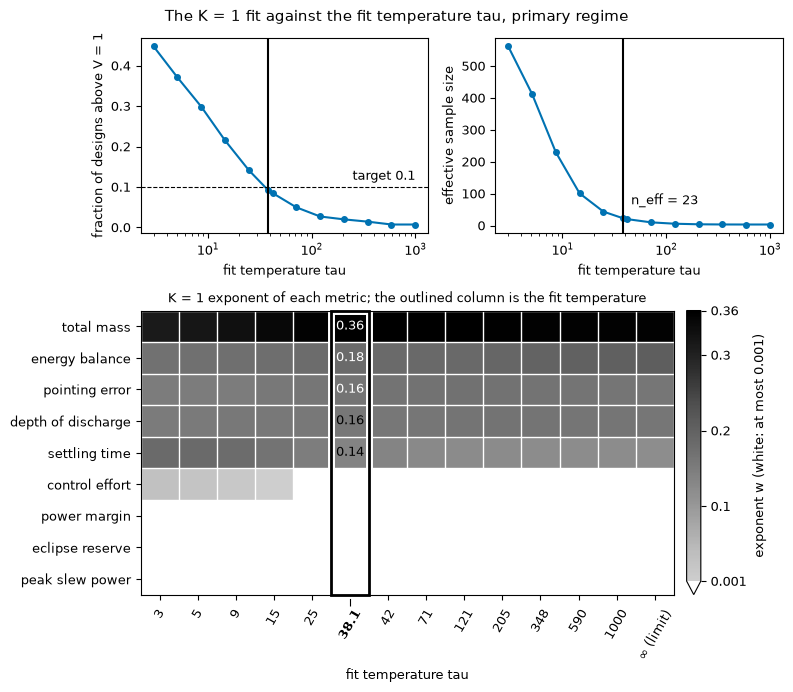

In [12]:
case.tau_sweep_figure(study, fit)

:::{figure} #fig-tau-sweep
:label: fig-tau
The K = 1 fit against the fit temperature tau (the temperature of the soft maximum in the fit), primary regime. Top: the fraction of designs above V = 1 (V is the invariant value; above 1 is beyond the fitted reference surface) with the target 0.1 (dashed), and the effective sample size with its value at the fit temperature; the vertical line is the fit temperature, where the fraction first meets the target. Bottom: the K = 1 exponent w of each metric at each temperature of the sweep, the last column the tau = infinity limit; rows ordered by the exponent at the fit temperature (the outlined column, values printed), white rows last in the table's order; a white cell is an exponent at most 0.001 (the glossary's participation threshold); the scale tops at the largest exponent of the sweep. [enlarge](figures/fig-tau-sweep.png)
:::


*Shows:* which metrics carry the K = 1 exponent at each fit temperature of the sweep, their rank and the exponents' values at the fit temperature; where the fit temperature sits on the fraction-above curve and what effective sample it leaves. *Does not show:* fit quality, the frontier or the designs near it, any K > 1 fit, why a metric has no exponent (carried by another metric, or a step function of the swaps: the n-lemma reading is the text's), nor the small values apart off the outlined column (the scale is linear). *Good for:* reading the n-lemma at the fit temperature; seeing what the fit temperature costs in effective sample.

In [13]:
from generate_findings import temperature_sentence

temperature_sentence(study, fit)

'The fit temperature is tau = 38.1: a fraction 0.092 of designs lies above V = 1 (the target is 0.10), the band 1/tau is 0.0262 and the effective sample size is 23.1 designs.'

In [14]:
from generate_findings import planted_sentence

planted_sentence()

'The planted table has 900 rows, 4 metrics and 3 planted facets.'

{numref}`Figure %s <fig-tau>` shows how the temperature is selected. Where the answer must be known, we plant it: a synthetic table with three facets of known exponents ({ref}`Appendix C <appendix-c>` gives its generator), from which {numref}`Section %s <sect-case-analysis>` asks whether the fit recovers them.

(sect-case-analysis)=
## Case analysis

We read the case as the method asks: what contends, how, and where designs sit (tables: {ref}`Appendix D <appendix-d>`; digits that hold: {ref}`D.11 <sub-d-11>`).

In [15]:
from generate_findings import recovery_sentence

recovery_sentence()

'**A known answer.** On 20 planted tables (400 rows, 4 metrics) the fit recovers all three facets to within 0.05 in 16, at the exact maximum and at temperature 50; the 4 failures have 5, 5, 6 and 11 frontier rows on their thinnest facet (<a href="supporting-material/#sub-d-14" target="_self" style="color:inherit;text-decoration:underline">Appendix D.14</a>).'

**One facet.** At K = 1 the fit reports one tension at the balanced point ({numref}`Figure %s <fig-plane-1>`).

In [16]:
fit3 = fits[3]
band = fit.band  # the K = 1 band at every K (gap G-9)

In [17]:
from generate_findings import k1_sentence

k1_sentence(study, fit)

'At K = 1 the exact-maximum fit has a 5-lemma across controls, power and energy, plus mass: total mass, energy balance, pointing error, depth of discharge and settling time contend, with exponents at the fit temperature from 0.14 to 0.36.'

:::{figure} figures/fig-planes-k1.png
:label: fig-plane-1
Log-metric plane of the K = 1 fit (primary regime) in its two heaviest metrics, total mass and energy balance. The line is the surface in this slice: the other seven metrics are held at the median of the near-frontier designs, so designs off that median fall on either side of it.
:::

*Shows:* the designs in the plane of the term's two heaviest metrics, total mass and energy balance, and the term's line there. *Does not show:* the other seven metrics (a design above the line here can be inside the surface) or the Pareto boundary. *Good for:* seeing the one-facet trade-off as a line with a slope.

**Three facets.** At K = 3 the tension separates into three facets with different contending sets: {numref}`Figure %s <fig-plane-3>` shows the surface bending where facets meet, {numref}`Figure %s <fig-chart-3>` shows each design's level read apart from its position along the surface, and {numref}`Figure %s <fig-tensions-3>` shows what trades off; the facet shares are in {ref}`Appendix D.3 <sub-d-3>`.

:::{figure} figures/fig-planes-k3.png
:label: fig-plane-3
Log-metric planes of the K = 3 fit, each a slice: the black line is the surface in the plane of two metrics, one straight segment per facet (named on it), with the other seven metrics held at the median of that facet's near-frontier designs, so a design can lie above the line here and still be inside the surface. In the bottom panel both metrics are set mostly by the discrete choices: the tracker grade places the pointing error in three columns (coarse at the left), and with the small or medium wheel peak slew power takes one value per wheel class and tracker grade (the six horizontal bands); the large wheel's designs form the lower cloud.
:::

*Shows:* three slices of the K = 3 surface, each facet a named straight piece of it, the kink where two meet, the band. *Does not show:* any grouping of designs, or metrics outside the drawn pair. *Good for:* seeing that the surface bends and that each facet is a piece of it.

:::{figure} figures/fig-chart-level.png
:label: fig-chart-3
The chart of the K = 3 fit: each design's position along the surface (Z0, the first of eight position coordinates, meaningless alone) against its level log V, the energy differential. The surface is the flat line log V = 0; grey: the near-frontier band; a design above the line lies beyond the surface.
:::

*Shows:* each design's level against its position along the surface, the surface as the flat line log V = 0. *Does not show:* what a position coordinate means (none alone), facets, or any grouping. *Good for:* reading a design's level apart from where it sits, and seeing where the designs reach the surface.

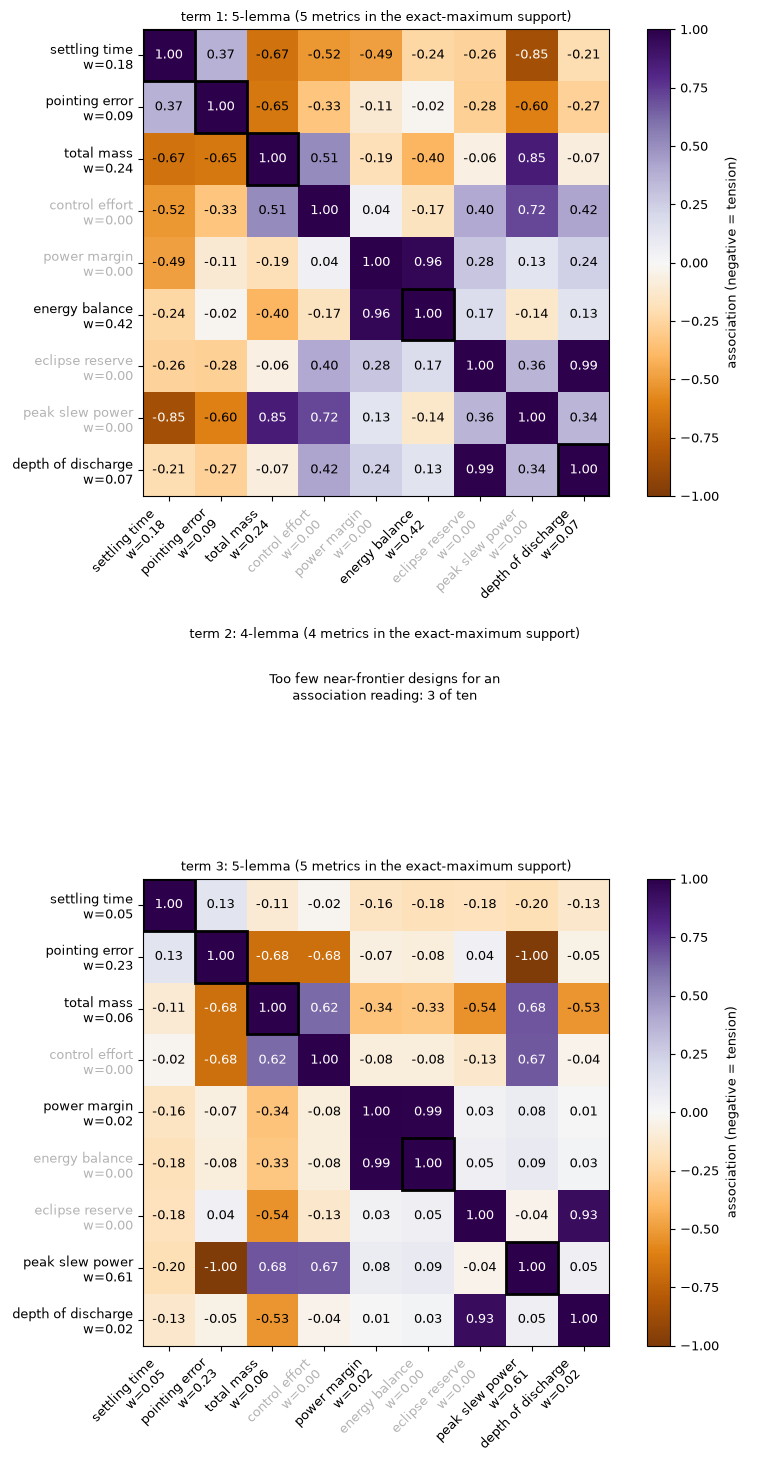

In [18]:
case.tension_figure(study, fit3, band=band)

:::{figure} #fig-tensions-k3
:label: fig-tensions-3
Association (the Pearson correlation of the log-metrics) among the near-frontier designs assigned to each K = 3 term (its cell), an analysis of those designs and not of the model (negative: tension). Outlined: the contending set, the support of the exact-maximum fit; w is the fitted exponent, small for some members. A term with fewer than ten near-frontier designs has no map; its panel says so. [enlarge](figures/fig-tensions-k3.png)
:::


*Shows:* which metrics trade on each term with enough near-frontier designs, and each term's contending set with its exponents. *Does not show:* causation, the exponents' uncertainty, designs. *Good for:* naming what trades against what on each term.

In [19]:
from generate_findings import k_sweep_sentence

k_sweep_sentence(study, fits)

'The mean slack falls from 0.243 at K = 1 to 0.182 at K = 2 and 0.146 at K = 3, at the temperatures 38, 94 and 113; refitted at the K = 1 temperature it falls to 0.13 and 0.09 (<a href="supporting-material/#sub-d-15" target="_self" style="color:inherit;text-decoration:underline">Appendix D.15</a>). The K = 3 facets have contending sets (exact-maximum supports) of 5, 4 and 5 metrics; control effort and peak slew power, absent from the K = 1 set, each lead a term of their own.'

Mean slack falls with K by construction and cannot choose it: three facets is the analyst's choice; the finding: their sets differ. A clustering with per-cluster correlations would describe the same designs; the facets add a model: each facet's fitted exponents give the elasticities at which its contending metrics trade ({prf:ref}`thm-elasticity`) and a level against which every design is read, while the association figures are an analysis of each cell's designs.

**Two regimes.** The same pipeline on the baseline regime separates the problem's contribution from the gains' ({numref}`Figure %s <fig-regimes-1>`).

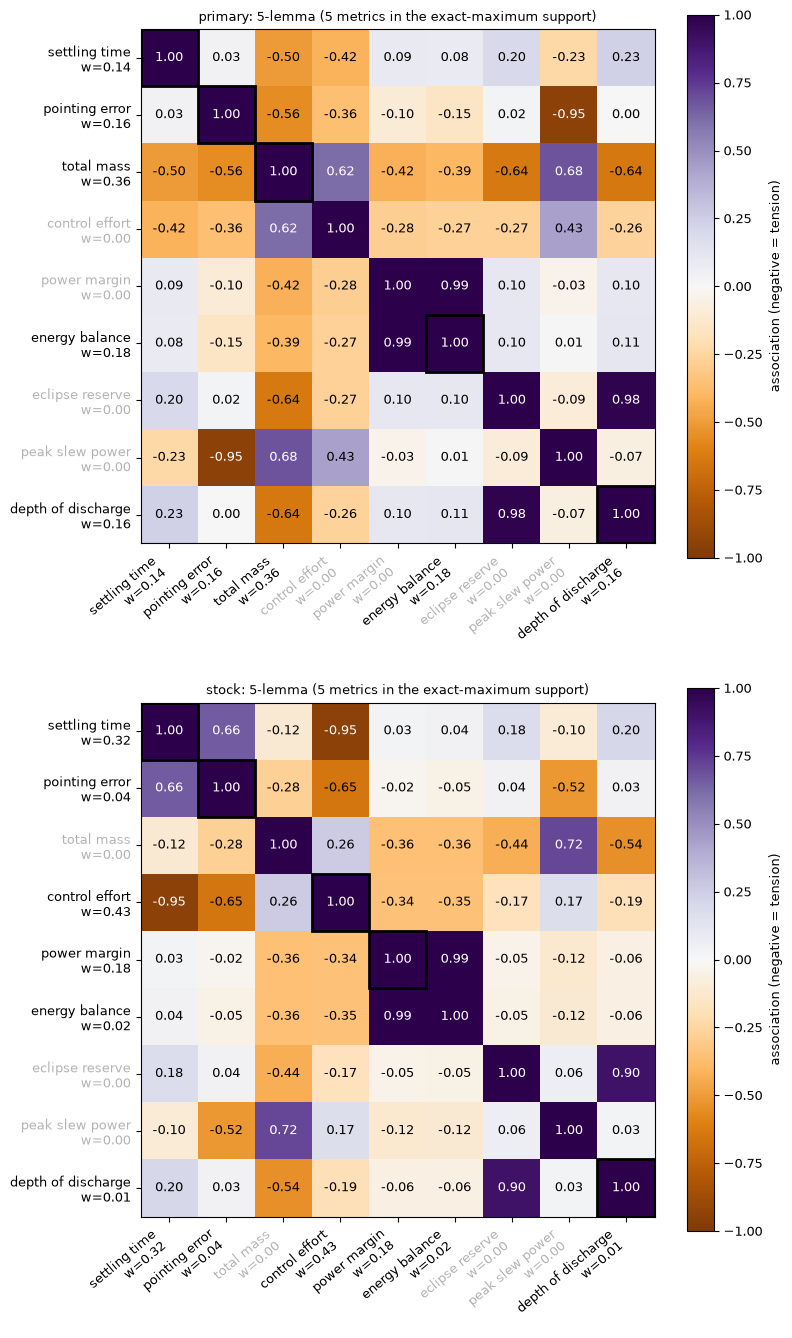

In [20]:
case.regime_figure()

:::{figure} #fig-regimes
:label: fig-regimes-1
The two regimes: association (the Pearson correlation of the log-metrics) among the near-frontier designs at K = 1 (one facet, so one cell: an analysis of those designs, not of the model), primary (aggressive controller gains) above, stock (stock gains) below; outlined: the contending set; w is the fitted exponent of each metric. [enlarge](figures/fig-regimes.png)
:::


*Shows:* the contending sets and associations of the two regimes side by side. *Does not show:* the K = 3 facets, or a selection of representative metrics (the outlines are the metrics that trade, not a pruning). *Good for:* seeing that the controller gains change what trades.

In [21]:
from generate_findings import regime_sentence

regime_sentence()

'The regimes return a 5-lemma and a 5-lemma sharing 3 metrics (depth of discharge, pointing error and settling time); the primary regime alone has energy balance and total mass, the stock regime alone control effort and power margin. The stock set spans controls plus power and energy: mass enters only in the primary regime.'

**Candidates.** Candidates are scored against the K = 1 fit ({ref}`Appendix D.7 <sub-d-7>`).

In [22]:
cand = case.candidate_table(study, fit)

In [23]:
from generate_findings import candidates_sentence

candidates_sentence(cand)

'The 3 measured candidates have lowest energy differential -0.197 and highest -0.153, and 0 of them lie beyond the fitted reference surface.'

**Propose, predict, check.** A regressor from configuration to chart coordinates predicts where proposals fall; we then measure them ({ref}`Appendix D.10 <sub-d-10>`). A proposal is the pooled configuration predicted nearest a hole of the four-metric chart, within a radius set by a rule: the 2nd percentile of the pool's nearest distances to the 300 most isolated holes (0.6222 here; on the earlier view with the slew time the rule gives 0.351, where 0.35 had been typed with no rule). Turning a predicted level into a bounded outcome is the analyst's task and can fail while the fit is certified: a prediction outside the quantity's admissible range is reported as invalid, never clipped.

In [24]:
reg = case.fit_regressor(study)

In [25]:
pc = case.predict_check(study, reg)

In [26]:
from generate_findings import predict_check_sentence

predict_check_sentence(pc, reg)

"Of 3 proposals, the predicted energy differential lies within the regressor's own band 1/tau = 0.0935 of the measured one for 3, and the predicted position within that band for 1; position errors run from 0.5 to 1.1 bands."

(sect-discussion)=
## Discussion

**Interpretation is human validation.** The fit reports what contends; whether that is an explicable trade-off is for an engineer to decide. The exponents and elasticities are features of the conditioned empirical model: they describe how the sampled designs trade, and not a causal exchange that changing a variable would reproduce. A hole in the chart is an opportunity only where the trade space is log-convex around it, which the data cannot prove. Novelty $V-1$ says how far beyond the fitted reference surface a design lies, not whether anyone wants it.

**Verify and validate.** Machine verification shows that a formula follows from its hypotheses and that the code agrees; it does not show that the hypotheses suit a table. That is human validation, which remains for a human: the conditioning, the choice of K and the reading of every finding. {ref}`Appendix B <appendix-b>` gives one line of code to read each proof step against; it cannot say that a sentence means what its line computes.

**Three claims.** A certified fit supports three claims of different strength. That the optimizer reached a local minimizer of the objective is the certificate ({prf:ref}`thm-certificate`). That the surface describes the observed designs is a claim about this table, read from its figures. That the fit holds for designs outside the table, or supports a decision, is a third claim the certificate does not make: it needs its own validation.


In [27]:
from generate_findings import predict_reading

predict_reading(pc, reg)

"**What propose, predict, check showed.** Two of them are one configuration. It showed that the regressor places the energy differential of a proposal within its band (3 of 3), the easy part. It did not show that it places the position along the frontier (1 of 3). All 3 fail the model's depth-of-discharge requirement: the proposer trains on the designs that settle, stay within the momentum budget and keep positive power, and its chart has no depth-of-discharge axis. Three proposals illustrate and do not estimate a rate. A predicted crossing of V = 1 remains a hypothesis."

**Why a frontier.** An answer far from the frontier is hard to justify, and the analysis must rerun on empirical data to support configuration management.

**Cross-application.** The input is a table of configurations and attributes. How the attributes were produced is a black box to the method, so the same functions serve a simulator, a physical test campaign or a human assessment. Another table runs through the same calls.

**Limits, in brief.** The fitted reference surface is a log-convex envelope. One facet is tangent at one place and is conservative off it. The exponents depend on the conditioning. Small samples determine exponents weakly. Designed samples, such as grids, are not independent observations: the exponents describe the sample and are not estimates with a sampling error. {ref}`Appendix E <appendix-e>` gives the ledger.

**PCA, what the contrast does and does not claim.** K = 1 finds one tension; several regional tensions need K > 1. A deflation-style search for successive tensions, as PCA extracts components, is a research question: we claim neither that it works nor that tensions are orthogonal. Tensions the sampling never exercised cannot appear.

**Novelty and white space.** By {prf:ref}`thm-invariant`, a design with $V=v$ is a frontier design scaled by $v$, so $V-1$ is a relative improvement, meaningful relative to the band $1/\tau$.

**The kernel direction.** The research question is which kernel expansions keep the programs geometric programs, so that the guarantees and reading rules carry over. Nothing here is built.

(sect-reproducibility)=
## Reproducibility and your own case

Every figure, table and reported number comes from a call into a tested module; {ref}`Appendix F <appendix-f>` gives the pinned toolchain, the environment of record, the commands and one row per item. To run your own table, supply configurations, attributes and a conditioning rule, and use the same calls; the package documentation is the user's guide.

(sect-future)=
## Future work and final remark

Future work follows the assumptions we named. Beyond one facet, K > 1 is built; beyond sharp weights with smoothing on request, a nonsmooth search on the tangent cones of the ridges, whose generalized gradient is the convex hull of the active normals, should tolerate the kinks. Beyond the analyst's K, selection rules. Beyond small K, scalability and speed, and a global search or certificate for the alternation (Q1). Beyond log-affine conditioning, GGP-compatible kernels, the generalization the search motivates. Beyond continuous variables within a category, discrete design variables. Beyond a log-convex envelope, the detection of dents and holes. Beyond illustrative hardware values, datasheet values. The search of {numref}`Section %s <sect-search>` needs a convergence theorem, and Q2 to Q4 need their own conditions. Other cases across the engineering lifecycle belong here too, the configuration management of a fielded system among them.

**Final remark.** A new capability or technology entering the design space could be given a novelty or impact score from how far above $V=1$ it is forecast to sit. We offer this as a hook for future exploration, not as a result.

(sect-process)=
## Acknowledgments and process

Work was done in supervisor-gated work packages: a written scope the author approved before execution, and a review afterwards. AI coding assistance (Claude Code, Anthropic) drafted code, derivation scripts and text inside those packages, in a process modelled on the harness described in [@zargham2026incose], whose deterministic checks and named human approver are the verification mechanism this paper inherits. The derivations are machine-checked. The author takes responsibility.

(sect-cited)=
## Works cited

```{bibliography}
```